# 01 — Retrieval

**Objective.** For each question, rank the pages of its PDF so that the evidence pages come first, and measure how often the top $k$ pages contain the evidence.

| | |
|---|---|
| **Input** | `questions.parquet`, `pages.parquet` from `00_document_processing.ipynb` |
| **Output** | `data/processed/mmlongbench_doc/rankings.parquet` (full BM25 ranking per question, native+OCR and native-only), `retrieval_per_question.csv`, `retrieval_summary.csv` |
| **Next** | `02_question_answering.ipynb` sends the top 5 pages to the model |

## Method

**BM25** scores a page $d$ for a query $q$ by summing over the query's distinct terms:

$$\text{score}(q, d) = \sum_{t \in q} \text{idf}(t)\,\frac{f(t,d)\,(k_1+1)}{f(t,d) + k_1\left(1 - b + b\,\frac{|d|}{\text{avgdl}}\right)}, \qquad \text{idf}(t) = \ln\left(1 + \frac{N - n_t + 0.5}{n_t + 0.5}\right)$$

- **idf:** a word on 2 of 41 pages is informative; a word on every page is not. The `1 +` (Lucene variant) keeps idf positive.
- **saturation** ($k_1 = 1.5$): the tenth occurrence of a word adds less than the first.
- **length normalisation** ($b = 0.75$): a long page does not win by containing more words.
- $N$, $n_t$ and avgdl are computed **per PDF**: MMLongBench-Doc asks each question about one document.

$k_1$ and $b$ are textbook defaults, **not tuned**. Text is lower-cased and split into alphanumeric tokens, with no stop-word list and no stemming. Ties are broken by page number, so the ranking is deterministic.

**Why BM25.** It needs no model, API or GPU, is deterministic and is easy to inspect, so it is a transparent floor that later retrievers must beat. Dense embeddings would match paraphrases but need a model choice (still open), and vision retrievers (e.g. ColPali) are out of scope for this baseline.

**Metrics.** For evidence pages $E$ and top-$k$ pages $R_k$:

$$\text{Recall@}k = \frac{|E \cap R_k|}{|E|}, \qquad \text{Hit@}k = \mathbf{1}\left[E \cap R_k \neq \varnothing\right].$$

Recall@k is the main metric because a third of the questions need several pages; Hit@k only asks for one. Under a uniformly random ranking of $n$ pages, the exact expectations are

$$\mathbb{E}[\text{Recall@}k] = \frac{\min(k, n)}{n}, \qquad \mathbb{E}[\text{Hit@}k] = 1 - \binom{n-|E|}{k} \Big/ \binom{n}{k}.$$

**Population:** answerable questions with at least one evidence page, excluding rows that cite page 0 (impossible under the 1-based convention). Unanswerable questions have no evidence to find.

In [1]:
from collections import Counter
from math import comb, isclose, log
from pathlib import Path
import ast
import json
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 160)


def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not find the repository root")


PROJECT_ROOT = find_project_root()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "mmlongbench_doc"
FROZEN_TEXT_RUN = PROJECT_ROOT / "experiments" / "frozen" / "mmlongbench_doc" / "text_run_20261119T220858Z_a351a532"
SETTINGS = {"bm25_k1": 1.5, "bm25_b": 0.75, "k_values": [1, 3, 5, 10], "generation_top_k": 5}

for name in ("questions.parquet", "pages.parquet"):
    assert (PROCESSED_DIR / name).is_file(), f"{name} is missing: run 00_document_processing.ipynb first"
questions = pd.read_parquet(PROCESSED_DIR / "questions.parquet")
subset = questions[questions["in_subset"]].reset_index(drop=True)
subset["evidence_pages"] = subset["evidence_pages"].map(list)
subset["evidence_sources"] = subset["evidence_sources"].map(list)
pages = pd.read_parquet(PROCESSED_DIR / "pages.parquet")
page_count = pages.groupby("doc_id")["page"].max()
print(f"{len(subset)} questions, {len(pages)} pages in {pages['doc_id'].nunique()} documents")

57 questions, 195 pages in 6 documents


## 1. Text preprocessing and term statistics

The example is the same question as in 00 (`mmlb-0033`, evidence page 6 of the 41-page `earlybird` deck).

In [2]:
TOKEN_PATTERN = re.compile(r"[a-z0-9]+")


def tokenize(text):
    return TOKEN_PATTERN.findall(str(text).lower())


example = subset[subset["answerable"] & (subset["n_evidence_pages"] == 1)].iloc[0]
example_page = example["evidence_pages"][0]
doc_pages = pages[pages["doc_id"] == example["doc_id"]]
page_tokens = {row.page: tokenize(row.text) for row in doc_pages.itertuples()}
N = len(page_tokens)
avgdl = np.mean([len(tokens) for tokens in page_tokens.values()])
document_frequency = Counter(token for tokens in page_tokens.values() for token in set(tokens))
idf = {token: log(1 + (N - n_t + 0.5) / (n_t + 0.5)) for token, n_t in document_frequency.items()}

query_terms = sorted(set(tokenize(example["question"])))
print(f"{example['qid']}: {example['question']}")
print(f"{example['doc_id']}: N={N} pages, avgdl={avgdl:.0f} tokens, vocabulary={len(idf):,} terms")
pd.DataFrame({
    "term": query_terms,
    "pages containing it (n_t)": [document_frequency.get(term, 0) for term in query_terms],
    "idf": [round(idf.get(term, 0.0), 3) for term in query_terms],
}).sort_values("idf", ascending=False).reset_index(drop=True)

mmlb-0033: How many more millions of dollars was the median exit valuation in the USA compared to Europe at the time of the presentation?
earlybird-110722143746-phpapp02_95.pdf: N=41 pages, avgdl=57 tokens, vocabulary=1,105 terms


,term,pages containing it (n_t),idf
0,millions,1,3.332
1,valuation,2,2.821
2,time,2,2.821
3,many,3,2.485
4,usa,3,2.485
5,median,3,2.485
6,was,3,2.485
7,exit,4,2.234
8,more,6,1.866
9,at,8,1.598


## 2. BM25 by hand on one question

In [3]:
k1, b = SETTINGS["bm25_k1"], SETTINGS["bm25_b"]


def term_contributions(query_terms, tokens):
    counts = Counter(tokens)
    length_factor = k1 * (1 - b + b * len(tokens) / max(avgdl, 1.0))
    return {term: idf[term] * counts[term] * (k1 + 1) / (counts[term] + length_factor) for term in query_terms if counts[term]}


page_scores = {page: sum(term_contributions(query_terms, tokens).values()) for page, tokens in page_tokens.items()}
top_pages = sorted(page_scores, key=lambda page: (-page_scores[page], page))[:5]
print("Top-5 pages:", top_pages, "| evidence page:", example_page)

breakdown = pd.DataFrame({f"page {p}": term_contributions(query_terms, page_tokens[p]) for p in [example_page, *top_pages[1:2]]}).fillna(0).round(2)
breakdown.loc["TOTAL"] = breakdown.sum()
breakdown

Top-5 pages: [6, 27, 2, 26, 30] | evidence page: 6


,page 6,page 27
at,1.33,1.32
europe,0.84,1.00
exit,3.72,2.78
in,0.27,0.40
median,3.72,0.00
of,1.08,0.89
the,0.53,0.70
time,2.35,0.00
usa,2.07,2.05
valuation,2.35,0.00


The evidence page ranks first because rare terms in this deck (`median`, `valuation`, `time`, idf 2.3–2.8) occur on page 6 and not on page 27, which scores mostly through common words (`to`, `was`). Question words that appear on no page (`dollars`, `compared`) contribute nothing, and BM25 cannot match `dollars` to `$`. This ranking exists only because of OCR: on native text, every page of this deck scores 0.

## 3. Rank every question

The same computation, wrapped into two helpers and checked against the step-by-step scores. Two text conditions use identical settings: **native + OCR fallback** (the main pipeline) and **native-only** (an ablation that isolates what OCR adds).

In [4]:
def build_bm25_index(page_texts):
    # page_texts: {page_number: text} for one PDF -> the statistics BM25 needs.
    tokens = {page: tokenize(text) for page, text in page_texts.items()}
    n_pages = len(tokens)
    frequency = Counter(token for page_tokens in tokens.values() for token in set(page_tokens))
    return {
        "term_counts": {page: Counter(page_tokens) for page, page_tokens in tokens.items()},
        "lengths": {page: len(page_tokens) for page, page_tokens in tokens.items()},
        "avgdl": float(np.mean([len(page_tokens) for page_tokens in tokens.values()])),
        "idf": {token: log(1 + (n_pages - n_t + 0.5) / (n_t + 0.5)) for token, n_t in frequency.items()},
    }


def bm25_rank(index, query, k1=SETTINGS["bm25_k1"], b=SETTINGS["bm25_b"]):
    # [(page, score), ...] for every page, best first; ties broken by page number.
    terms = set(tokenize(query))
    scored = []
    for page, counts in index["term_counts"].items():
        length_factor = k1 * (1 - b + b * index["lengths"][page] / max(index["avgdl"], 1.0))
        scored.append((page, sum(index["idf"][t] * counts[t] * (k1 + 1) / (counts[t] + length_factor) for t in terms if counts[t])))
    return sorted(scored, key=lambda item: (-item[1], item[0]))


def rank_subset(text_column):
    indexes = {doc_id: build_bm25_index(dict(zip(group["page"].tolist(), group[text_column]))) for doc_id, group in pages.groupby("doc_id")}
    return indexes, [[page for page, _ in bm25_rank(indexes[row.doc_id], row.question)] for row in subset.itertuples()]


bm25_indexes, subset["ranking"] = rank_subset("text")
_, subset["ranking_native"] = rank_subset("native_text")

helper_scores = dict(bm25_rank(bm25_indexes[example["doc_id"]], example["question"]))
assert all(isclose(helper_scores[page], page_scores[page], abs_tol=1e-12) for page in page_scores)

# Regression: the full ranking (every page, every position) equals the one the frozen text run used.
frozen_ranking = pd.read_csv(FROZEN_TEXT_RUN / "scored_predictions.csv").set_index("qid")["ranking"].map(ast.literal_eval)
identical = sum(row.ranking == frozen_ranking[row.qid] for row in subset.itertuples())
assert identical == len(subset)
print(f"Helper reproduces the by-hand scores; full rankings identical to the frozen run for {identical} of {len(subset)} questions.")
subset[["qid", "evidence_pages"]].assign(top_10=subset["ranking"].map(lambda r: r[:10])).head(6)

Helper reproduces the by-hand scores; full rankings identical to the frozen run for 57 of 57 questions.


,qid,evidence_pages,top_10
0,mmlb-0033,[6],"[6, 27, 2, 26, 30, 33, 28, 39, 38, 10]"
1,mmlb-0034,[11],"[11, 6, 26, 2, 27, 33, 17, 7, 19, 31]"
2,mmlb-0035,"[11, 13, 15, 16, 21, 22, 23, 24, 25, 26, 27, 31, 38]","[39, 9, 30, 2, 31, 18, 11, 22, 10, 16]"
3,mmlb-0036,"[14, 19, 20, 33, 37]","[38, 30, 2, 5, 7, 23, 39, 10, 6, 26]"
4,mmlb-0037,[33],"[31, 32, 19, 30, 13, 17, 33, 34, 39, 2]"
5,mmlb-0038,[],"[19, 31, 13, 30, 17, 2, 32, 34, 27, 33]"


## 4. Retrieval metrics

In [5]:
def recall_at_k(evidence, ranking, k):
    return len(set(evidence) & set(ranking[:k])) / len(set(evidence))


def hit_at_k(evidence, ranking, k):
    return float(bool(set(evidence) & set(ranking[:k])))


def random_hit_at_k(n_pages, n_evidence, k):
    return 1.0 if k >= n_pages else 1 - comb(n_pages - n_evidence, k) / comb(n_pages, k)


population = subset[subset["answerable"] & (subset["n_evidence_pages"] > 0)].copy()
population = population[~population["evidence_pages"].map(lambda evidence: 0 in evidence)]
population["page_count"] = population["doc_id"].map(page_count)
native_words = pages.set_index(["doc_id", "page"])["native_words"]
population["evidence_native_words"] = [float(np.mean([native_words[(d, p)] for p in e])) for d, e in zip(population["doc_id"], population["evidence_pages"])]

for k in SETTINGS["k_values"]:
    for prefix, column in (("", "ranking"), ("native_", "ranking_native")):
        population[f"{prefix}recall@{k}"] = [recall_at_k(e, r, k) for e, r in zip(population["evidence_pages"], population[column])]
        population[f"{prefix}hit@{k}"] = [hit_at_k(e, r, k) for e, r in zip(population["evidence_pages"], population[column])]
    population[f"random_recall@{k}"] = [min(k, n) / n for n in population["page_count"]]
    population[f"random_hit@{k}"] = [random_hit_at_k(int(n), len(set(e)), k) for e, n in zip(population["evidence_pages"], population["page_count"])]

retrieval_summary = pd.DataFrame([
    {"k": k,
     "BM25 native-only Recall@k": population[f"native_recall@{k}"].mean(),
     "BM25 Recall@k": population[f"recall@{k}"].mean(),
     "random Recall@k": population[f"random_recall@{k}"].mean(),
     "BM25 Hit@k": population[f"hit@{k}"].mean(),
     "random Hit@k": population[f"random_hit@{k}"].mean()}
    for k in SETTINGS["k_values"]
]).set_index("k").round(3)

# Regression against the frozen run's retrieval summary.
frozen_summary = pd.read_csv(FROZEN_TEXT_RUN / "retrieval_summary.csv", index_col="k")
pd.testing.assert_frame_equal(retrieval_summary, frozen_summary[retrieval_summary.columns], check_dtype=False)
print(f"Population: {len(population)} answerable questions ({int((population['n_evidence_pages'] > 1).sum())} cross-page) "
      f"in {population['doc_id'].nunique()} documents. Unqualified BM25 = native + OCR text. Identical to the frozen run.")
retrieval_summary

Population: 40 answerable questions (18 cross-page) in 6 documents. Unqualified BM25 = native + OCR text. Identical to the frozen run.


,BM25 native-only Recall@k,BM25 Recall@k,random Recall@k,BM25 Hit@k,random Hit@k
k,,,,,
1,0.200,0.346,0.035,0.400,0.068
3,0.321,0.608,0.106,0.725,0.189
5,0.358,0.689,0.176,0.800,0.293
10,0.474,0.809,0.352,0.900,0.506


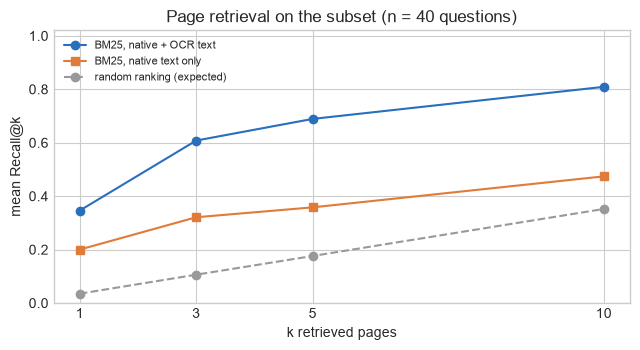

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ks = retrieval_summary.index
ax.plot(ks, retrieval_summary["BM25 Recall@k"], marker="o", color="#2A6FBB", label="BM25, native + OCR text")
ax.plot(ks, retrieval_summary["BM25 native-only Recall@k"], marker="s", color="#E07B39", label="BM25, native text only")
ax.plot(ks, retrieval_summary["random Recall@k"], marker="o", linestyle="--", color="#999999", label="random ranking (expected)")
ax.set(xlabel="k retrieved pages", ylabel="mean Recall@k", ylim=(0, 1.02), xticks=list(ks),
       title=f"Page retrieval on the subset (n = {len(population)} questions)")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

In [7]:
gen_k = SETTINGS["generation_top_k"]
by_document = population.groupby("doc_id").agg(
    questions=("qid", "size"),
    native_only=(f"native_recall@{gen_k}", "mean"),
    native_ocr=(f"recall@{gen_k}", "mean"),
    random=(f"random_recall@{gen_k}", "mean"),
).round(3)
by_document["pages OCR'd"] = by_document.index.map(pages.groupby("doc_id")["ocr_used"].sum())
print(f"Recall@{gen_k} per document:")
display(by_document)

by_source = (population.explode("evidence_sources").groupby("evidence_sources")
             .agg(questions=("qid", "size"), native_only=(f"native_recall@{gen_k}", "mean"), native_ocr=(f"recall@{gen_k}", "mean"))
             .sort_values("questions", ascending=False).round(3))
print(f"Recall@{gen_k} per evidence source (a question with several sources counts once per source; small groups are noisy):")
by_source

Recall@5 per document:

,questions,native_only,native_ocr,random,pages OCR'd
doc_id,,,,,
2210.02442v1.pdf,6,0.556,0.556,0.208,0
PG_2020.05.21_International-Cooperation-COVID_FINAL.pdf,7,0.857,0.857,0.192,1
bdf54dxa.pdf,5,0.000,0.500,0.093,53
earlybird-110722143746-phpapp02_95.pdf,7,0.000,0.440,0.122,41
germanwingsdigitalcrisisanalysis-150403064828-conversion-gate01_95.pdf,11,0.091,0.788,0.217,23
watch_d.pdf,4,1.000,1.000,0.185,2


Recall@5 per evidence source (a question with several sources counts once per source; small groups are noisy):


,questions,native_only,native_ocr
evidence_sources,,,
Figure,17,0.255,0.735
Chart,15,0.467,0.738
Pure-text (Plain-text),10,0.400,0.750
Table,7,0.143,0.571
Generalized-text (Layout),4,0.250,0.375


### Second page-convention check, using the retriever

BM25 never sees the annotations. If benchmark page numbers were shifted by one, the top-ranked page would tend to sit **next to** an annotated page rather than on it.

In [8]:
offset_counts = pd.Series({
    label: int(sum(ranking[0] - offset in set(evidence) for evidence, ranking in zip(population["evidence_pages"], population["ranking"])))
    for offset, label in {-1: "top-1 page == p - 1", 0: "top-1 page == p (1-based)", 1: "top-1 page == p + 1 (0-based)"}.items()
}, name="questions")
assert offset_counts["top-1 page == p (1-based)"] > max(offset_counts["top-1 page == p - 1"], offset_counts["top-1 page == p + 1 (0-based)"])
offset_counts.to_frame()

,questions
top-1 page == p - 1,5
top-1 page == p (1-based),16
top-1 page == p + 1 (0-based),5


## 5. Failure cases: what BM25 misses

In [9]:
misses = population[population[f"hit@{gen_k}"] == 0].assign(top_pages=lambda f: f["ranking"].map(lambda r: r[:gen_k]))
print(f"{len(misses)} of {len(population)} questions have no evidence page in the top {gen_k}:")
misses[["qid", "question", "evidence_pages", "evidence_sources", "top_pages", "evidence_native_words"]]

8 of 40 questions have no evidence page in the top 5:


,qid,question,evidence_pages,evidence_sources,top_pages,evidence_native_words
3,mmlb-0036,How many human quotes are provided with source in this document?,"[14, 19, 20, 33, 37]","[Figure, Generalized-text (Layout)]","[38, 30, 2, 5, 7]",0.0
4,mmlb-0037,Which two magazines' opinions are selected to illustrate the situa...,[33],"[Generalized-text (Layout), Figure]","[31, 32, 19, 30, 13]",0.0
6,mmlb-0039,"In the slides, how many charts compare between ONLY US and Europe?","[6, 7, 8, 11, 18, 23, 24, 25, 28, 30]",[Chart],"[17, 2, 9, 40, 21]",0.0
14,mmlb-0313,Which step in the figure at the top of page 10 poured the salt to ...,[11],"[Figure, Pure-text (Plain-text)]","[25, 27, 9, 10, 26]",0.0
20,mmlb-0319,How many possible problems does the diswasher may encounter before...,"[30, 31, 32]",[Table],"[29, 51, 10, 3, 42]",0.0
32,mmlb-0727,How many more Tweets are attributed to Germanwings than Lufthansa?,[16],[Table],"[18, 19, 7, 13, 4]",0.0
45,mmlb-0740,What are the incident and report dates? Save your answer as a list...,"[1, 2]",[Pure-text (Plain-text)],"[7, 13, 3, 4, 20]",0.0
53,mmlb-0767,What are the optimizers used in this research?,"[14, 15]",[Table],"[1, 9, 18, 6, 3]",348.5


Three error types appear:

1. **Counting or aggregation over many pages** (`mmlb-0036`, `mmlb-0039`): the evidence spans 5–10 pages, which no top-5 list can cover.
2. **Mainly visual evidence:** the question names objects in a figure (e.g. magazine covers), and the OCR text shares few words with it.
3. **Printed page labels are not physical pages** (`mmlb-0313`): "the figure at the top of page 10" is physical page 11, because the document's printed numbering is offset from the PDF index.

## Save the rankings

In [10]:
max_k = max(SETTINGS["k_values"])
subset[["qid", "doc_id", "ranking", "ranking_native"]].to_parquet(PROCESSED_DIR / "rankings.parquet", index=False)
metric_columns = [c for c in population.columns if c.startswith(("recall@", "hit@", "native_", "random_"))]
population.assign(ranking=population["ranking"].map(lambda r: r[:max_k]), ranking_native=population["ranking_native"].map(lambda r: r[:max_k]))[
    ["qid", "doc_id", "answer_format", "evidence_pages", "evidence_sources", "page_count", "evidence_native_words", "ranking", "ranking_native", *metric_columns]
].to_csv(PROCESSED_DIR / "retrieval_per_question.csv", index=False)
retrieval_summary.to_csv(PROCESSED_DIR / "retrieval_summary.csv")
print("Saved rankings.parquet, retrieval_per_question.csv and retrieval_summary.csv to", PROCESSED_DIR.relative_to(PROJECT_ROOT))

Saved rankings.parquet, retrieval_per_question.csv and retrieval_summary.csv to data/processed/mmlongbench_doc


## Validation

In [11]:
# 1. Every ranking is a permutation of its document's 1-based page numbers.
assert all(sorted(r) == list(range(1, page_count[d] + 1)) for d, r in zip(subset["doc_id"], subset["ranking"]))
assert all(sorted(r) == list(range(1, page_count[d] + 1)) for d, r in zip(subset["doc_id"], subset["ranking_native"]))
# 2. Metric ranges and monotonicity; Hit@k >= Recall@k.
assert all(population[c].between(0, 1).all() for c in metric_columns)
assert retrieval_summary["BM25 Recall@k"].is_monotonic_increasing
assert (retrieval_summary["BM25 Hit@k"] >= retrieval_summary["BM25 Recall@k"] - 1e-12).all()
# 3. Unanswerable questions never enter the retrieval metrics.
assert population["answerable"].all()
# 4. Recall and Hit differ on a cross-page case: one of two evidence pages retrieved.
assert recall_at_k([3, 7], [7, 1, 2], 1) == 0.5 and hit_at_k([3, 7], [7, 1, 2], 1) == 1.0
# 5. Regression values quoted in the README.
assert retrieval_summary.loc[5, "BM25 Recall@k"] == 0.689 and retrieval_summary.loc[5, "BM25 Hit@k"] == 0.8
print("All validation checks passed.")

All validation checks passed.


## Interpretation

- **OCR is the largest retrieval effect.** With identical BM25 settings, Recall@5 rises from 0.358 (native text only) to **0.689** (native + OCR). On the three image-only documents the native ranking is just page order, and native-only Recall@5 there (0.000, 0.000, 0.091) is *below* the random reference (0.093–0.217): evidence is rarely on the first pages.
- **BM25 is far above chance** (Recall@5 0.689 versus 0.176 for a random ranking), yet 31 % of evidence pages are still outside the top 5, which is all the model will see. **Hit@5 is 0.800**: cross-page questions often retrieve one evidence page but not all.
- **The retriever confirms the page convention:** the top-1 page coincides with an annotated page $p$ far more often (16) than with $p \pm 1$ (5 and 5).

**Limitations.** 40 questions in 6 documents: per-document recall varies widely, and another seed could move the averages by about 0.1. Evidence-source groups contain 4–17 questions; treat their differences as hypotheses. BM25 is untuned.

**Failure case to remember.** On native text, every `germanwings` page scores 0, BM25 returns pages in document order, and Recall@5 is 0.091, below the random reference of 0.217. Nothing raises an error.

**Next:** `02_question_answering.ipynb` gives the top 5 pages, or the annotated evidence pages, to the model as text or as images.